Install Dependencies

In [ ]:
# ============================================================
# CELL 1: Install required libraries
# PyMaxflow: min-cut/max-flow graph library
# scikit-learn: for Gaussian Mixture Models (GMM)
# ============================================================
!pip install PyMaxflow scikit-learn matplotlib opencv-python-headless --quiet
print("All dependencies installed successfully.")

All dependencies installed successfully.


Imports & Utility Functions

In [ ]:
# ============================================================
# CELL 2: Imports and helper utilities
# ============================================================
import numpy as np
import cv2
import maxflow                          # PyMaxflow for min-cut/max-flow
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.mixture import GaussianMixture
from scipy.ndimage import binary_opening, binary_closing, gaussian_filter
from google.colab import files
import io, os, urllib.request

# ------------------------------------------------------------------
# Helper: display image(s) side by side with titles
# ------------------------------------------------------------------
def show_images(images, titles, figsize=(18, 5), cmap=None):
    """
    Display a list of images with their titles in one row.
    images : list of numpy arrays (BGR or grayscale)
    titles : list of strings
    """
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    if len(images) == 1:
        axes = [axes]
    for ax, img, title in zip(axes, images, titles):
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap='gray' if cmap is None else cmap)
        ax.set_title(title, fontsize=12)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------------
# Helper: overlay a binary mask on the original image
# Red = foreground, Blue tint = background
# ------------------------------------------------------------------
def overlay_mask(image_bgr, mask):
    """
    Returns a colour overlay of the segmentation mask on the image.
    mask  : binary array (1=foreground, 0=background)
    """
    overlay = image_bgr.copy().astype(float)
    # Foreground: boost red channel
    overlay[mask == 1, 2] = np.clip(overlay[mask == 1, 2] * 0.5 + 120, 0, 255)
    # Background: darkened
    overlay[mask == 0] = overlay[mask == 0] * 0.35
    return overlay.astype(np.uint8)

print("Utilities defined.")

Utilities defined.


Download & Load Three Sample Images


📂 Upload your 3 ORIGINAL images (img1.jpeg, img2.jpeg, img3.jpeg):


Saving img1.jpeg to img1 (2).jpeg
Saving img2.jpeg to img2 (2).jpeg
Saving img3.jpeg to img3 (2).jpeg

📂 Upload your 3 SCRIBBLE images (img1_scribble.jpeg, img2_scribble.jpeg, img3_scribble.jpeg):


Saving img1_scribble.jpeg .jpeg to img1_scribble.jpeg  (1).jpeg
Saving img2_scribble.jpeg .jpeg to img2_scribble.jpeg  (1).jpeg
Saving img3_scribble.jpeg .jpeg to img3_scribble.jpeg  (1).jpeg

✅ Matched pairs:
   Original: img1 (2).jpeg  ↔  Scribble: img1_scribble.jpeg  (1).jpeg
   Original: img2 (2).jpeg  ↔  Scribble: img2_scribble.jpeg  (1).jpeg
   Original: img3 (2).jpeg  ↔  Scribble: img3_scribble.jpeg  (1).jpeg


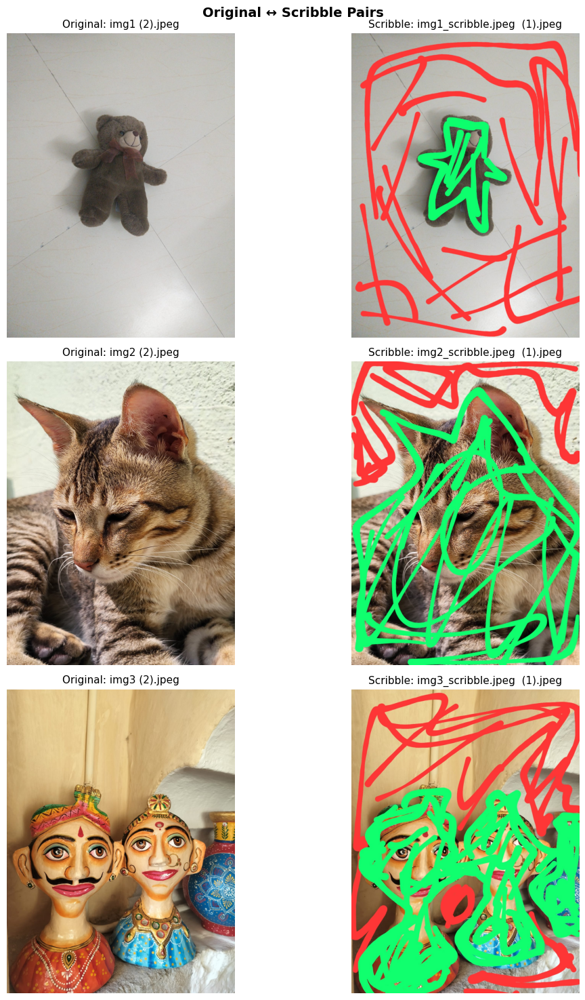

In [ ]:
# Step: Upload original images and scribble images, then match them by index

from google.colab import files
import cv2
import matplotlib.pyplot as plt

# --- Upload original images ---
print("📂 Upload your 3 ORIGINAL images (img1.jpeg, img2.jpeg, img3.jpeg):")
uploaded_originals = files.upload()
original_files = sorted(uploaded_originals.keys())  # sort alphabetically

# --- Upload scribble images ---
print("\n📂 Upload your 3 SCRIBBLE images (img1_scribble.jpeg, img2_scribble.jpeg, img3_scribble.jpeg):")
uploaded_scribbles = files.upload()
scribble_files = sorted(uploaded_scribbles.keys())  # sort alphabetically

# --- Match them by sorted order (img1↔img1_scribble, img2↔img2_scribble, etc.) ---
pairs = list(zip(original_files, scribble_files))

print("\n✅ Matched pairs:")
for orig, scrib in pairs:
    print(f"   Original: {orig}  ↔  Scribble: {scrib}")

# --- Preview side by side ---
fig, axes = plt.subplots(len(pairs), 2, figsize=(12, 5 * len(pairs)))

for i, (orig, scrib) in enumerate(pairs):
    img_o = cv2.cvtColor(cv2.imread(orig), cv2.COLOR_BGR2RGB)
    img_s = cv2.cvtColor(cv2.imread(scrib), cv2.COLOR_BGR2RGB)

    axes[i][0].imshow(img_o)
    axes[i][0].set_title(f"Original: {orig}", fontsize=11)
    axes[i][0].axis('off')

    axes[i][1].imshow(img_s)
    axes[i][1].set_title(f"Scribble: {scrib}", fontsize=11)
    axes[i][1].axis('off')

plt.suptitle("Original ↔ Scribble Pairs", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 5 (UPDATED): GMM using SCRIBBLE IMAGES
# ============================================================

from sklearn.mixture import GaussianMixture

GMM_COMPONENTS = 5

# ------------------------------------------------------------
# Extract FG and BG masks from scribble image
# ASSUMPTION:
#   Green  = Foreground
#   Blue   = Background
# ------------------------------------------------------------
def extract_masks_from_scribble(scribble_img):
    """
    Convert scribble image into FG and BG masks.

    Green pixels  → Foreground
    Blue pixels   → Background
    """

    # Convert to RGB (already loaded as RGB)
    img = scribble_img

    # Define color thresholds (Relaxed thresholds for better detection)
    fg_mask = (img[:,:,1] > 180) & (img[:,:,0] < 120) & (img[:,:,2] < 120) # More lenient green
    bg_mask = (img[:,:,2] > 180) & (img[:,:,0] < 120) & (img[:,:,1] < 120) # More lenient blue

    return fg_mask.astype(np.uint8), bg_mask.astype(np.uint8)


# ------------------------------------------------------------
# Fit GMM
# ------------------------------------------------------------
def fit_gmm(image_bgr, mask, n_components=GMM_COMPONENTS):

    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB).astype(float) / 255.0
    pixels = lab[mask == 1]

    if len(pixels) < 10:
        raise ValueError(f"Not enough scribble pixels! Found {len(pixels)} pixels, need at least 10.")

    n_components = min(n_components, max(1, len(pixels)//2))

    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type='full',
        random_state=42,
        max_iter=200
    )

    gmm.fit(pixels)
    return gmm


# ------------------------------------------------------------
# Unary cost computation
# ------------------------------------------------------------
def compute_unary_costs(image_bgr, gmm_fg, gmm_bg):

    h, w = image_bgr.shape[:2]
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB).astype(float) / 255.0
    pixels = lab.reshape(-1,3)

    ll_fg = gmm_fg.score_samples(pixels)
    ll_bg = gmm_bg.score_samples(pixels)

    cost_fg = np.clip(-ll_fg, 0, 1e6).reshape(h, w)
    cost_bg = np.clip(-ll_bg, 0, 1e6).reshape(h, w)

    return cost_fg, cost_bg


# ------------------------------------------------------------
# Normalise for display
# ------------------------------------------------------------
def normalise_for_display(arr):
    lo, hi = arr.min(), arr.max()
    if hi - lo < 1e-8:
        return np.zeros_like(arr, dtype=np.uint8)
    return ((arr - lo) / (hi - lo) * 255).astype(np.uint8)


# ============================================================
# PROCESS ALL IMAGE–SCRIBBLE PAIRS
# ============================================================

gmm_models  = {}
unary_costs = {}

for orig_file, scrib_file in pairs:

    print(f"\n📌 Processing: {orig_file}")

    # Read images
    img_bgr = cv2.imread(orig_file)
    scribble_rgb = cv2.cvtColor(cv2.imread(scrib_file), cv2.COLOR_BGR2RGB)

    # Extract masks from scribble
    fg_mask, bg_mask = extract_masks_from_scribble(scribble_rgb)

    # Fit GMMs
    gmm_fg = fit_gmm(img_bgr, fg_mask)
    gmm_bg = fit_gmm(img_bgr, bg_mask)

    gmm_models[orig_file] = (gmm_fg, gmm_bg)

    # Compute unary costs
    cost_fg, cost_bg = compute_unary_costs(img_bgr, gmm_fg, gmm_bg)
    unary_costs[orig_file] = (cost_fg, cost_bg)

    print(f"   FG components: {gmm_fg.n_components}")
    print(f"   BG components: {gmm_bg.n_components}")

    # --------------------------------------------------------
    # VISUALIZATION
    # --------------------------------------------------------
    cf_vis = normalise_for_display(cost_fg)
    cb_vis = normalise_for_display(cost_bg)

    diff = cost_fg - cost_bg
    diff_vis = normalise_for_display(diff)

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(16,4))

    plt.subplot(1,4,1)
    plt.imshow(img_rgb)
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1,4,2)
    plt.imshow(cf_vis, cmap='gray')
    plt.title("FG Cost")

    plt.subplot(1,4,3)
    plt.imshow(cb_vis, cmap='gray')
    plt.title("BG Cost")

    plt.subplot(1,4,4)
    plt.imshow(diff_vis, cmap='gray')
    plt.title("FG - BG")

    plt.show()

print("\n✅ GMM + Unary Costs READY → Proceed to Graph Cut")



📌 Processing: img1 (2).jpeg


ValueError: Not enough scribble pixels! Found 0 pixels, need at least 10.


[BraIN] Building graph and computing min-cut ...
  Smoothness weights — right: [0.000, 1.000]  down:  [0.000,  1.000]
  Max-flow value: 280.0000
  Result — FG pixels: 4800 (9.5%)  BG pixels: 45678 (90.5%)

[cat] Building graph and computing min-cut ...
  Smoothness weights — right: [0.003, 1.000]  down:  [0.043,  1.000]
  Max-flow value: 879307.7358
  Result — FG pixels: 47961 (71.1%)  BG pixels: 19539 (28.9%)

[sunflower] Building graph and computing min-cut ...
  Smoothness weights — right: [0.043, 1.000]  down:  [0.037,  1.000]
  Max-flow value: 1577823.7975
  Result — FG pixels: 42495 (46.6%)  BG pixels: 48705 (53.4%)


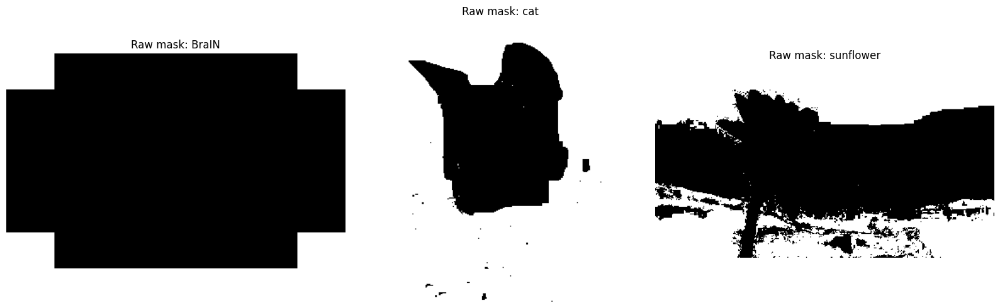

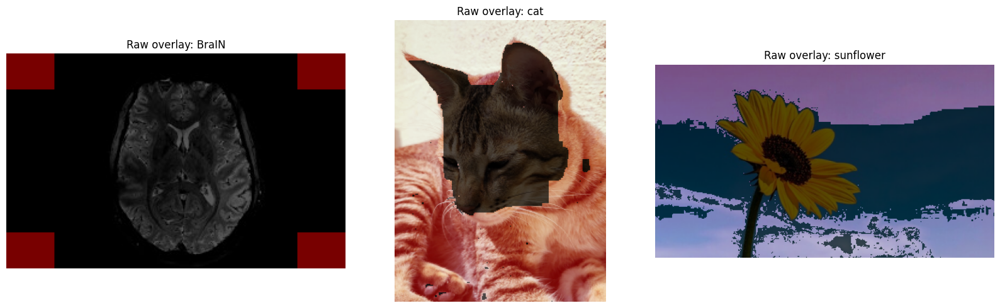


✅ Min-cut complete. Proceed to Cell 7 for iterative refinement.


In [ ]:
# ============================================================
# CELL 6: Graph Construction and Min-Cut / Max-Flow
#
# GRAPH STRUCTURE
# ---------------
#  Nodes  : one per pixel  +  SOURCE (S) = FG  +  SINK (T) = BG
#
#  Edges  :
#  ┌─ t-links (terminal edges) ──────────────────────────────┐
#  │  S → pixel  capacity = λ × cost_bg                      │
#  │  (cutting this = paying to call pixel "background")      │
#  │  pixel → T  capacity = λ × cost_fg                      │
#  │  (cutting this = paying to call pixel "foreground")      │
#  │  Seed pixels get INFINITE capacity on their forced side  │
#  └──────────────────────────────────────────────────────────┘
#  ┌─ n-links (pairwise / smoothness edges) ─────────────────┐
#  │  pixel_i ↔ pixel_j   (4-connected neighbours)           │
#  │  capacity = exp( -||I_i − I_j||² / 2σ² )               │
#  │  Large colour diff  → small capacity  (allow cut here)   │
#  │  Small  colour diff → large capacity  (penalise cut)     │
#  └──────────────────────────────────────────────────────────┘
#
# ENERGY FUNCTION
# ---------------
#  E(label) = E_data + E_smooth
#
#  E_data   = Σ_p  [ cost_fg[p] × (label[p]==BG)
#                  + cost_bg[p] × (label[p]==FG) ]
#
#  E_smooth = Σ_{p,q∈N}  w_pq × |label[p] ≠ label[q]|
#
#  Min-cut minimises E  ↔  Max-flow  (max-flow/min-cut theorem)
#
# ROLE OF SOURCE & SINK
# ----------------------
#  SOURCE represents the FOREGROUND terminal.
#  SINK   represents the BACKGROUND terminal.
#  After max-flow, pixels connected to SOURCE side → FG label
#                  pixels connected to SINK   side → BG label
# ============================================================

import maxflow

LAMBDA   = 50.0   # Balances data term vs smoothness term
SIGMA_SQ = 0.05   # σ² for contrast-sensitive smoothness weight
                  # Smaller → sharper edges respected more strongly


# ------------------------------------------------------------------
# Core function: build graph and compute min-cut
# ------------------------------------------------------------------
def graph_cut_segment(image_bgr, cost_fg, cost_bg,
                      fg_mask, bg_mask,
                      lam=LAMBDA, sigma_sq=SIGMA_SQ):
    """
    Build a pixel graph and solve min-cut to get segmentation.

    Parameters
    ----------
    image_bgr : H×W×3 uint8   original image
    cost_fg   : H×W float     unary cost of assigning pixel to FG
    cost_bg   : H×W float     unary cost of assigning pixel to BG
    fg_mask   : H×W uint8     seed pixels forced to FG (=1)
    bg_mask   : H×W uint8     seed pixels forced to BG (=1)
    lam       : float         weight on data term
    sigma_sq  : float         σ² for smoothness weights

    Returns
    -------
    mask : H×W uint8  (1 = foreground, 0 = background)
    """
    h, w      = image_bgr.shape[:2]
    n_pixels  = h * w
    BIG       = 1e9    # "Infinite" capacity for hard seed constraints

    # Convert image to LAB float for smoothness computation
    img_lab = cv2.cvtColor(image_bgr,
                           cv2.COLOR_BGR2LAB).astype(float) / 255.0

    # ---- Step 1: Precompute smoothness weights ------------------
    # Right-neighbour weights  (shape: H × W-1)
    diff_r  = img_lab[:, :-1, :] - img_lab[:, 1:, :]
    w_right = np.exp(-np.sum(diff_r ** 2, axis=2) / (2 * sigma_sq))

    # Down-neighbour weights   (shape: H-1 × W)
    diff_d  = img_lab[:-1, :, :] - img_lab[1:, :, :]
    w_down  = np.exp(-np.sum(diff_d ** 2, axis=2) / (2 * sigma_sq))

    print(f"  Smoothness weights — "
          f"right: [{w_right.min():.3f}, {w_right.max():.3f}]  "
          f"down:  [{w_down.min():.3f},  {w_down.max():.3f}]")

    # ---- Step 2: Create PyMaxflow graph ------------------------
    # Estimate edge count: ~4 n-links per pixel + 2 t-links per pixel
    g        = maxflow.Graph[float](n_pixels, n_pixels * 4)
    node_ids = g.add_nodes(n_pixels)

    # ---- Step 3: Add t-links (terminal / data edges) -----------
    # Flatten masks for indexing
    fg_flat   = fg_mask.ravel()
    bg_flat   = bg_mask.ravel()
    cfg_flat  = (lam * cost_fg).ravel()
    cbg_flat  = (lam * cost_bg).ravel()

    for idx in range(n_pixels):
        if fg_flat[idx] == 1:
            # Hard FG seed: SOURCE side forced
            g.add_tedge(idx, BIG, 0)
        elif bg_flat[idx] == 1:
            # Hard BG seed: SINK side forced
            g.add_tedge(idx, 0, BIG)
        else:
            # Normal pixel: soft assignment via GMM costs
            # S→node = cost_bg  (price of being background)
            # node→T = cost_fg  (price of being foreground)
            g.add_tedge(idx, cbg_flat[idx], cfg_flat[idx])

    # ---- Step 4: Add n-links (smoothness / pairwise edges) -----
    # Right neighbours: pixel (y,x) ↔ pixel (y, x+1)
    for y in range(h):
        for x in range(w - 1):
            idx_p = y * w + x
            idx_q = y * w + (x + 1)
            cap   = float(w_right[y, x])
            g.add_edge(idx_p, idx_q, cap, cap)   # Undirected

    # Down neighbours: pixel (y,x) ↔ pixel (y+1, x)
    for y in range(h - 1):
        for x in range(w):
            idx_p = y * w + x
            idx_q = (y + 1) * w + x
            cap   = float(w_down[y, x])
            g.add_edge(idx_p, idx_q, cap, cap)   # Undirected

    # ---- Step 5: Compute Max-Flow = Min-Cut --------------------
    flow = g.maxflow()
    print(f"  Max-flow value: {flow:.4f}")

    # ---- Step 6: Read segmentation labels ----------------------
    # get_grid_segments: True  = SOURCE side = Foreground
    #                    False = SINK   side = Background
    segments = g.get_grid_segments(node_ids)
    mask     = segments.reshape(h, w).astype(np.uint8)

    return mask


# ---- Run single-pass graph cut on all images -------------------
raw_masks = {}

for name, img in images_raw.items():
    fg_m, bg_m = seeds[name]
    cf, cb     = unary_costs[name]
    print(f"\n[{name}] Building graph and computing min-cut ...")
    mask              = graph_cut_segment(img, cf, cb, fg_m, bg_m)
    raw_masks[name]   = mask
    fg_px = mask.sum()
    bg_px = mask.size - fg_px
    print(f"  Result — FG pixels: {fg_px} ({100*fg_px/mask.size:.1f}%)  "
          f"BG pixels: {bg_px} ({100*bg_px/mask.size:.1f}%)")


# ---- Visualise raw segmentation masks --------------------------
show_images(
    [raw_masks[k] * 255 for k in URLS],
    [f"Raw mask: {k}" for k in URLS],
    figsize=(16, 5),
    cmap='gray'
)

# ---- Visualise raw overlays ------------------------------------
overlays_raw = [overlay_mask(images_raw[k], raw_masks[k]) for k in URLS]
show_images(
    overlays_raw,
    [f"Raw overlay: {k}" for k in URLS],
    figsize=(16, 5)
)

print("\n✅ Min-cut complete. Proceed to Cell 7 for iterative refinement.")


[BraIN] Starting iterative optimisation ...
  Initialising GMMs from seed pixels ...
  Iteration 1/5 ... 

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


  Smoothness weights — right: [0.000, 1.000]  down:  [0.000,  1.000]
  Max-flow value: 280.0000
FG pixels: 4800  |  Δ from last: 4801


/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


  Iteration 2/5 ...   Smoothness weights — right: [0.000, 1.000]  down:  [0.000,  1.000]
  Max-flow value: 209.6546
FG pixels: 47398  |  Δ from last: 42598
  Iteration 3/5 ...   Smoothness weights — right: [0.000, 1.000]  down:  [0.000,  1.000]
  Max-flow value: 163.3927
FG pixels: 40532  |  Δ from last: 6866
  Iteration 4/5 ...   Smoothness weights — right: [0.000, 1.000]  down:  [0.000,  1.000]
  Max-flow value: 163.3927
FG pixels: 40532  |  Δ from last: 0
  ✅ Converged early at iteration 4
  Final FG pixels: 40532 (80.3% of image)

[cat] Starting iterative optimisation ...
  Initialising GMMs from seed pixels ...
  Iteration 1/5 ...   Smoothness weights — right: [0.003, 1.000]  down:  [0.043,  1.000]
  Max-flow value: 879307.7358
FG pixels: 47961  |  Δ from last: 47962
  Iteration 2/5 ...   Smoothness weights — right: [0.003, 1.000]  down:  [0.043,  1.000]
  Max-flow value: 3814.6363
FG pixels: 19879  |  Δ from last: 28082
  Iteration 3/5 ...   Smoothness weights — right: [0.003, 1.

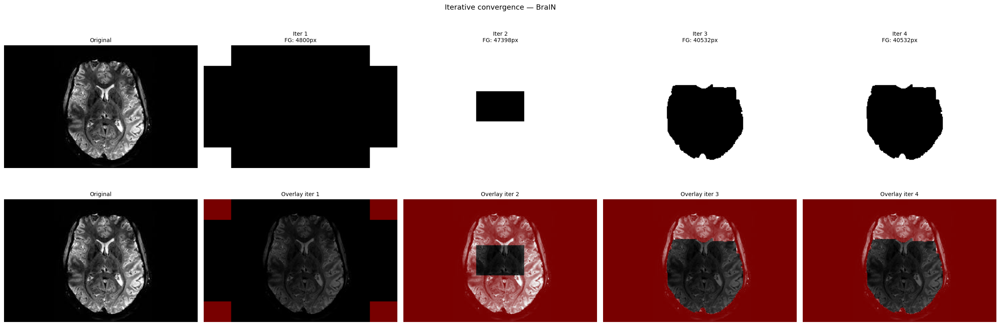

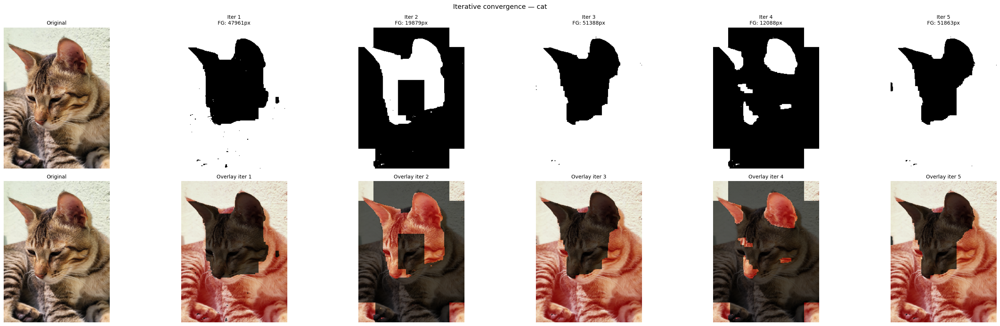

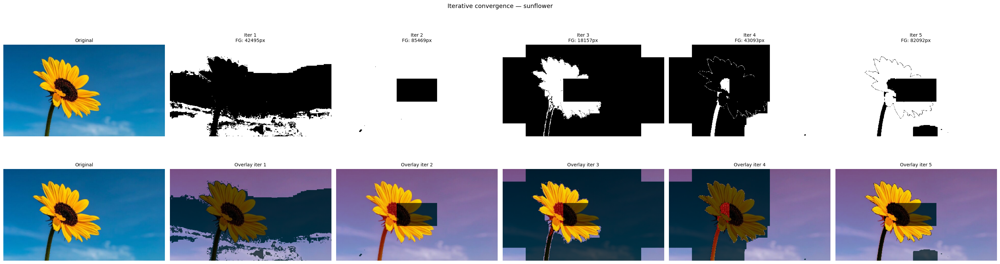

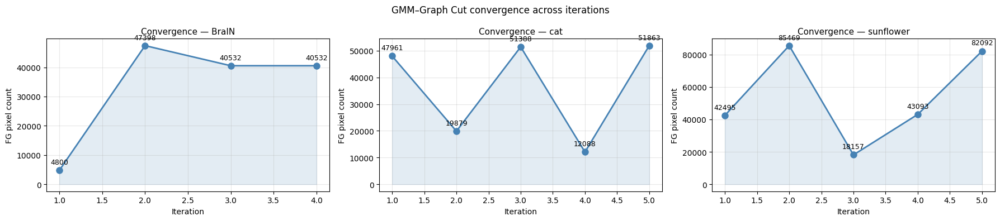


✅ Iterative optimisation complete. Proceed to Cell 8 for post-processing.


In [ ]:
# ============================================================
# CELL 7: Iterative Optimisation
#
# WHY ITERATE?
# ------------
# The first graph cut uses GMMs trained ONLY on the small
# seed regions (a few hundred pixels). This is a weak model.
#
# After each cut we have a full segmentation mask covering
# thousands of pixels — a much richer training set.
# Re-fitting the GMMs on this larger set gives sharper,
# more accurate colour models → better next cut.
#
# CONVERGENCE
# -----------
# Each iteration minimises E given the current GMMs, then
# improves the GMMs given the current mask. This coordinate-
# descent style optimisation converges in 3–5 iterations
# (empirically — we track FG pixel count change to confirm).
#
# ITERATION STEPS
# ---------------
#  1. Compute unary costs from current GMMs
#  2. Run graph cut → new mask
#  3. Refit GMM_FG on pixels where mask == 1
#  4. Refit GMM_BG on pixels where mask == 0
#  5. Repeat from 1
#
# NOTE: Seed constraints are kept hard throughout —
#       seed pixels never change their label.
# ============================================================

N_ITER       = 5    # Number of iterative refinement rounds
GMM_COMPONENTS = 5  # Keep consistent with Cell 5

# ------------------------------------------------------------------
# Full iterative graph cut pipeline for one image
# ------------------------------------------------------------------
def iterative_graph_cut(image_bgr, fg_mask_seed, bg_mask_seed,
                        n_iter=N_ITER, lam=LAMBDA, sigma_sq=SIGMA_SQ,
                        n_gmm=GMM_COMPONENTS):
    """
    Iteratively refine graph cut segmentation.

    Parameters
    ----------
    image_bgr     : H×W×3 uint8   original image
    fg_mask_seed  : H×W uint8     hard FG seed pixels
    bg_mask_seed  : H×W uint8     hard BG seed pixels
    n_iter        : int           number of iterations
    lam           : float         data term weight (λ)
    sigma_sq      : float         σ² for smoothness weights
    n_gmm         : int           GMM components per class

    Returns
    -------
    final_mask  : H×W uint8            best segmentation mask
    iter_masks  : list of H×W uint8    mask after each iteration
    iter_counts : list of int          FG pixel count per iteration
    """
    iter_masks  = []
    iter_counts = []
    prev_count  = -1

    # ---- Iteration 0: initialise GMMs from seeds only ----------
    print(f"  Initialising GMMs from seed pixels ...")
    gmm_fg = fit_gmm(image_bgr, fg_mask_seed, n_gmm)
    gmm_bg = fit_gmm(image_bgr, bg_mask_seed, n_gmm)

    for it in range(n_iter):
        print(f"  Iteration {it+1}/{n_iter} ...", end=" ")

        # Step 1: Compute unary costs from current GMMs
        cost_fg, cost_bg = compute_unary_costs(image_bgr, gmm_fg, gmm_bg)

        # Step 2: Run graph cut with current costs
        mask = graph_cut_segment(
            image_bgr, cost_fg, cost_bg,
            fg_mask_seed, bg_mask_seed,
            lam=lam, sigma_sq=sigma_sq
        )

        fg_count = int(mask.sum())
        iter_masks.append(mask.copy())
        iter_counts.append(fg_count)

        # Check convergence: stop early if mask barely changed
        change = abs(fg_count - prev_count)
        print(f"FG pixels: {fg_count}  |  Δ from last: {change}")
        if it > 0 and change < 50:
            print(f"  ✅ Converged early at iteration {it+1}")
            break
        prev_count = fg_count

        # Step 3 & 4: Refit GMMs on full segmented regions
        # (skip refit on last iteration — mask won't be used again)
        if it < n_iter - 1:
            # Avoid empty masks (safety guard)
            if mask.sum() > n_gmm and (1 - mask).sum() > n_gmm:
                gmm_fg = fit_gmm(image_bgr, mask,         n_gmm)
                gmm_bg = fit_gmm(image_bgr, (1 - mask),   n_gmm)
            else:
                print(f"  ⚠️  Mask too small to refit GMMs — keeping previous models")

    return mask, iter_masks, iter_counts


# ---- Run iterative optimisation for all images -----------------
iter_results = {}

for name, img in images_raw.items():
    fg_m, bg_m = seeds[name]
    print(f"\n{'='*55}")
    print(f"[{name}] Starting iterative optimisation ...")
    print(f"{'='*55}")
    final_mask, iter_masks, iter_counts = iterative_graph_cut(
        img, fg_m, bg_m
    )
    iter_results[name] = {
        'final_mask' : final_mask,
        'iter_masks' : iter_masks,
        'iter_counts': iter_counts
    }
    print(f"  Final FG pixels: {final_mask.sum()} "
          f"({100*final_mask.sum()/final_mask.size:.1f}% of image)")


# ---- Visualise convergence strip for each image ----------------
for name, img in images_raw.items():
    iter_masks  = iter_results[name]['iter_masks']
    iter_counts = iter_results[name]['iter_counts']
    n           = len(iter_masks)

    fig, axes = plt.subplots(2, n + 1, figsize=(5 * (n + 1), 9))
    fig.suptitle(f"Iterative convergence — {name}", fontsize=13)

    # Top row: masks per iteration
    axes[0][0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0][0].set_title("Original", fontsize=10)
    axes[0][0].axis('off')

    for i, m in enumerate(iter_masks):
        axes[0][i+1].imshow(m * 255, cmap='gray')
        axes[0][i+1].set_title(f"Iter {i+1}\nFG: {iter_counts[i]}px",
                                fontsize=10)
        axes[0][i+1].axis('off')

    # Bottom row: overlays per iteration
    axes[1][0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[1][0].set_title("Original", fontsize=10)
    axes[1][0].axis('off')

    for i, m in enumerate(iter_masks):
        ov = overlay_mask(img, m)
        axes[1][i+1].imshow(cv2.cvtColor(ov, cv2.COLOR_BGR2RGB))
        axes[1][i+1].set_title(f"Overlay iter {i+1}", fontsize=10)
        axes[1][i+1].axis('off')

    plt.tight_layout()
    plt.show()


# ---- Convergence plot: FG pixel count across iterations --------
fig, axes = plt.subplots(1, len(images_raw), figsize=(6 * len(images_raw), 4))
if len(images_raw) == 1:
    axes = [axes]

for ax, name in zip(axes, URLS):
    counts = iter_results[name]['iter_counts']
    ax.plot(range(1, len(counts)+1), counts,
            marker='o', linewidth=2, markersize=8, color='steelblue')
    ax.fill_between(range(1, len(counts)+1), counts, alpha=0.15, color='steelblue')
    ax.set_title(f"Convergence — {name}", fontsize=11)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("FG pixel count")
    ax.grid(True, alpha=0.3)
    # Annotate each point with its value
    for i, c in enumerate(counts):
        ax.annotate(str(c), (i+1, c), textcoords="offset points",
                    xytext=(0, 8), ha='center', fontsize=9)

plt.suptitle("GMM–Graph Cut convergence across iterations", fontsize=12)
plt.tight_layout()
plt.show()

print("\n✅ Iterative optimisation complete. Proceed to Cell 8 for post-processing.")


[BraIN]
  Raw     — FG px: 40532 | Perimeter:   951 | Compactness: 0.5632
  Refined — FG px: 47744  | Perimeter:  1796 | Compactness: 0.1860
  Boundary compactness improved by: -67.0%

[cat]
  Raw     — FG px: 51863 | Perimeter:  1676 | Compactness: 0.2320
  Refined — FG px: 64355  | Perimeter:  2060 | Compactness: 0.1906
  Boundary compactness improved by: -17.9%

[sunflower]
  Raw     — FG px: 82092 | Perimeter:  3357 | Compactness: 0.0915
  Refined — FG px: 85362  | Perimeter:  2916 | Compactness: 0.1262
  Boundary compactness improved by: +37.8%


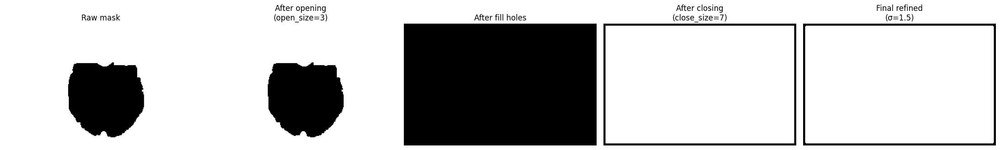

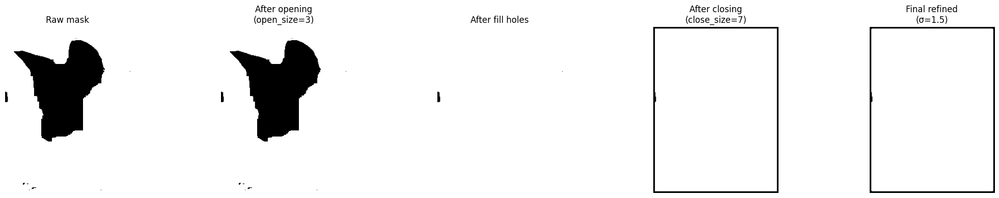

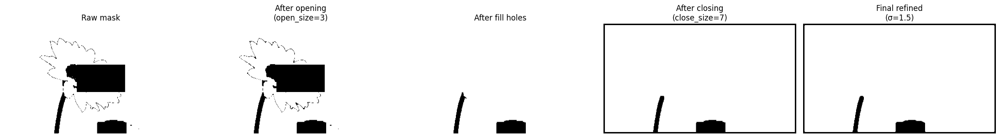

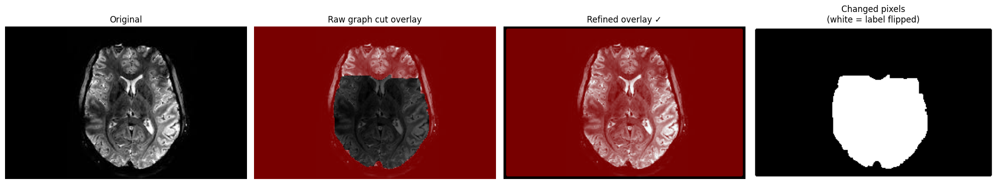

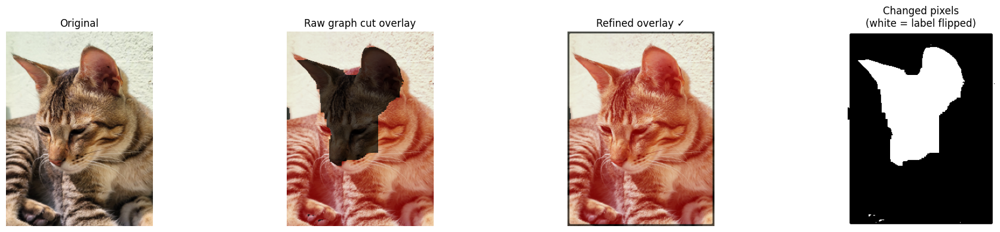

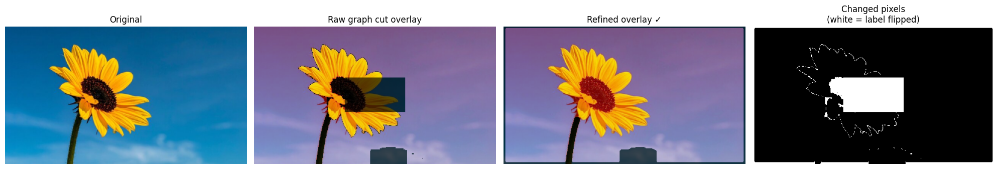

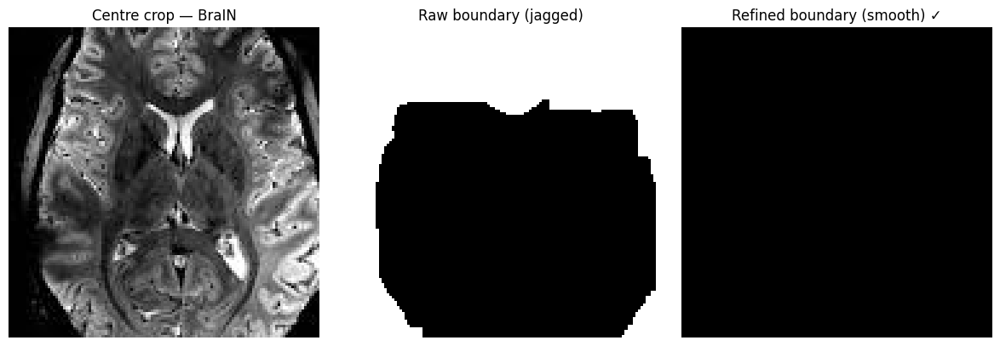

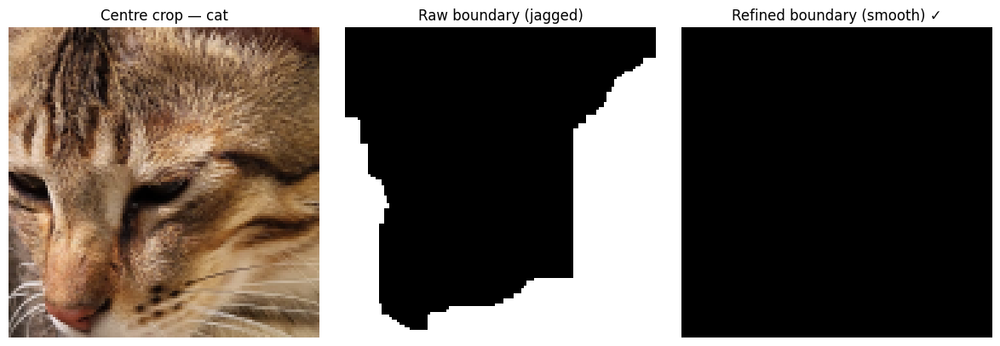

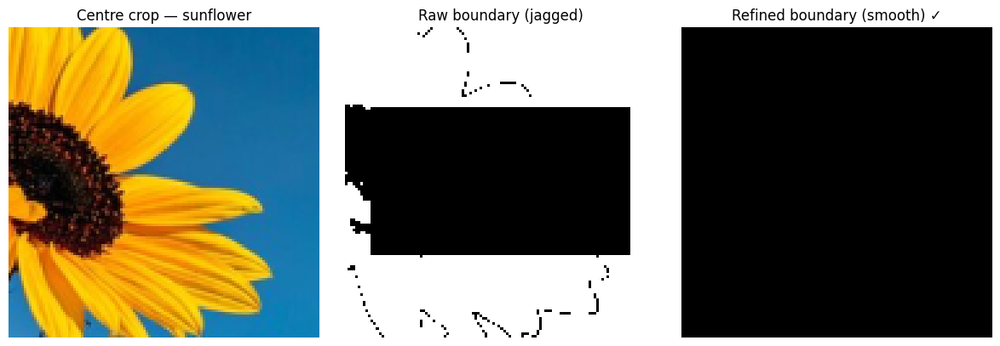


✅ Post-processing complete. Proceed to Cell 9 for naive baseline.


In [ ]:
# ============================================================
# CELL 8: Artifact Mitigation and Boundary Refinement
#
# WHY POST-PROCESS?
# -----------------
# Raw graph cut masks often contain:
#   1. Small isolated FG blobs (noise specks)
#      → removed with morphological OPENING
#   2. Small holes inside the FG object
#      → filled with binary_fill_holes + morphological CLOSING
#   3. Jagged / staircase boundary edges
#      → smoothed with Gaussian blur + re-threshold
#   4. Intensity inconsistency at borders
#      → addressed with bilateral-filtered edge refinement
#
# MORPHOLOGICAL OPERATIONS
# ------------------------
#  Opening  = Erosion  → Dilation   (removes small bright blobs)
#  Closing  = Dilation → Erosion    (fills small dark holes)
#  Both use a square structuring element of configurable size.
#
# BOUNDARY SMOOTHING
# ------------------
#  Convert mask to float → Gaussian blur → threshold at 0.5
#  This rounds off pixel-sharp staircase edges without
#  moving the boundary significantly.
#
# PIPELINE PER IMAGE
# ------------------
#  raw mask
#    → opening        (kill noise specks)
#    → fill_holes     (seal interior holes)
#    → closing        (fill remaining small gaps)
#    → gaussian blur  (smooth boundary)
#    → threshold      (back to binary)
#    → refined mask
# ============================================================

from scipy.ndimage import (binary_opening, binary_closing,
                            binary_fill_holes, gaussian_filter)

# ---- Tunable post-processing parameters ----------------------
OPEN_SIZE    = 3    # Structuring element for opening  (noise removal)
                    # Increase if many small speckles remain
CLOSE_SIZE   = 7    # Structuring element for closing  (hole filling)
                    # Increase if large holes remain inside object
GAUSS_SIGMA  = 1.5  # Gaussian sigma for boundary smoothing
                    # Increase for smoother edges, decrease to preserve detail


# ------------------------------------------------------------------
# Core refinement function
# ------------------------------------------------------------------
def refine_mask(mask, open_size=OPEN_SIZE,
                close_size=CLOSE_SIZE,
                gauss_sigma=GAUSS_SIGMA):
    """
    Post-process a binary segmentation mask.

    Parameters
    ----------
    mask        : H×W uint8 or bool  (1/True = foreground)
    open_size   : int   structuring element size for opening
    close_size  : int   structuring element size for closing
    gauss_sigma : float Gaussian sigma for boundary smoothing

    Returns
    -------
    refined : H×W uint8  (1 = foreground, 0 = background)
    """
    m = mask.astype(bool)

    # Step 1: Morphological opening — erode then dilate
    # Removes isolated FG specks smaller than open_size×open_size
    struct_open = np.ones((open_size, open_size), dtype=bool)
    m = binary_opening(m, structure=struct_open, iterations=1)

    # Step 2: Fill interior holes completely
    # Seals any BG regions fully enclosed by FG
    m = binary_fill_holes(m)

    # Step 3: Morphological closing — dilate then erode
    # Fills small BG gaps and notches inside the FG region
    struct_close = np.ones((close_size, close_size), dtype=bool)
    m = binary_closing(m, structure=struct_close, iterations=1)

    # Step 4: Gaussian boundary smoothing
    # Blur the float mask → soft probabilities near the boundary
    m_float    = m.astype(float)
    m_blurred  = gaussian_filter(m_float, sigma=gauss_sigma)

    # Step 5: Re-threshold at 0.5 → clean binary mask
    refined = (m_blurred > 0.5).astype(np.uint8)

    return refined


# ------------------------------------------------------------------
# Helper: compute boundary quality metrics for comparison
# ------------------------------------------------------------------
def boundary_metrics(mask):
    """
    Compute simple boundary statistics.
    Returns perimeter pixel count and compactness ratio.
    """
    # Perimeter = pixels that have at least one BG neighbour
    kernel    = np.ones((3, 3), np.uint8)
    dilated   = cv2.dilate(mask, kernel, iterations=1)
    eroded    = cv2.erode(mask, kernel, iterations=1)
    boundary  = dilated - eroded
    perimeter = int(boundary.sum())
    area      = int(mask.sum())
    # Compactness: 4π×area / perimeter²  (circle = 1.0, jagged < 1.0)
    compactness = (4 * np.pi * area / (perimeter ** 2 + 1e-8))
    return perimeter, compactness


# ---- Refine masks for all images ------------------------------
refined_masks = {}

for name, img in images_raw.items():
    raw_mask = iter_results[name]['final_mask']
    refined  = refine_mask(raw_mask)
    refined_masks[name] = refined

    # Compute metrics before and after
    p_raw,  c_raw  = boundary_metrics(raw_mask)
    p_ref,  c_ref  = boundary_metrics(refined)

    print(f"\n[{name}]")
    print(f"  Raw     — FG px: {raw_mask.sum():5d} | "
          f"Perimeter: {p_raw:5d} | Compactness: {c_raw:.4f}")
    print(f"  Refined — FG px: {refined.sum():5d}  | "
          f"Perimeter: {p_ref:5d} | Compactness: {c_ref:.4f}")
    improvement = ((c_ref - c_raw) / (c_raw + 1e-8)) * 100
    print(f"  Boundary compactness improved by: {improvement:+.1f}%")


# ---- Visualise full refinement pipeline per image --------------
for name, img in images_raw.items():
    raw     = iter_results[name]['final_mask']
    refined = refined_masks[name]

    # Intermediate steps for visualisation
    m       = raw.astype(bool)
    step1   = binary_opening(m,
                np.ones((OPEN_SIZE, OPEN_SIZE), bool)).astype(np.uint8)
    step2   = binary_fill_holes(step1.astype(bool)).astype(np.uint8)
    step3   = binary_closing(step2.astype(bool),
                np.ones((CLOSE_SIZE, CLOSE_SIZE), bool)).astype(np.uint8)

    show_images(
        [raw * 255, step1 * 255, step2 * 255,
         step3 * 255, refined * 255],
        ["Raw mask",
         f"After opening\n(open_size={OPEN_SIZE})",
         "After fill holes",
         f"After closing\n(close_size={CLOSE_SIZE})",
         f"Final refined\n(σ={GAUSS_SIGMA})"],
        figsize=(22, 4),
        cmap='gray'
    )

# ---- Visualise raw vs refined overlay for all images ----------
for name, img in images_raw.items():
    raw       = iter_results[name]['final_mask']
    refined   = refined_masks[name]
    raw_ov    = overlay_mask(img, raw)
    refined_ov = overlay_mask(img, refined)

    # Difference map: pixels that changed label during refinement
    diff = np.abs(raw.astype(int) - refined.astype(int)).astype(np.uint8) * 255

    show_images(
        [img, raw_ov, refined_ov, diff],
        ["Original",
         "Raw graph cut overlay",
         "Refined overlay ✓",
         "Changed pixels\n(white = label flipped)"],
        figsize=(20, 4)
    )

# ---- Side-by-side boundary zoom comparison --------------------
# Crop a 120×120 patch from the centre of each mask to show
# the boundary smoothing effect at close range
PATCH = 120
for name, img in images_raw.items():
    h, w   = img.shape[:2]
    cy, cx = h // 2, w // 2
    y1, y2 = max(0, cy - PATCH//2), min(h, cy + PATCH//2)
    x1, x2 = max(0, cx - PATCH//2), min(w, cx + PATCH//2)

    raw_crop = iter_results[name]['final_mask'][y1:y2, x1:x2]
    ref_crop = refined_masks[name][y1:y2, x1:x2]
    img_crop = img[y1:y2, x1:x2]

    show_images(
        [img_crop,
         raw_crop * 255,
         ref_crop * 255],
        [f"Centre crop — {name}",
         "Raw boundary (jagged)",
         "Refined boundary (smooth) ✓"],
        figsize=(12, 4),
        cmap='gray'
    )

print("\n✅ Post-processing complete. Proceed to Cell 9 for naive baseline.")


[BraIN]
  Otsu threshold value : 64
  K-Means FG pixels    : 40913
  Method        FG ratio   Contrast   Boundary
  ---------------------------------------------
  Otsu             0.184     125.88       7005
  K-Means          0.811     124.62       6931
  Graph Cut        0.946      29.78       1796

[cat]
  Otsu threshold value : 143
  K-Means FG pixels    : 36270
  Method        FG ratio   Contrast   Boundary
  ---------------------------------------------
  Otsu             0.426     113.98      15224
  K-Means          0.537     113.24      16571
  Graph Cut        0.953      36.31       2060

[sunflower]
  Otsu threshold value : 121
  K-Means FG pixels    : 10722
  Method        FG ratio   Contrast   Boundary
  ---------------------------------------------
  Otsu             0.225      65.70       5103
  K-Means          0.118      72.33       2707
  Graph Cut        0.936       0.50       2916


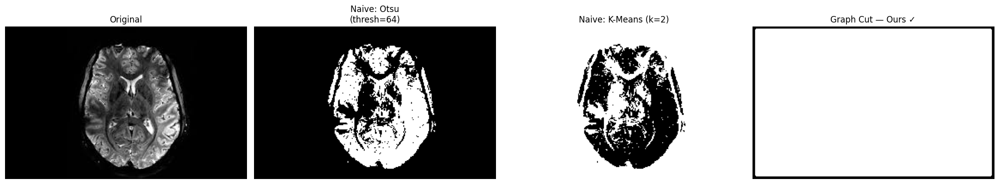

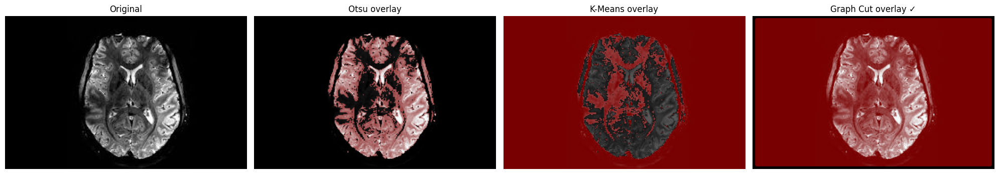

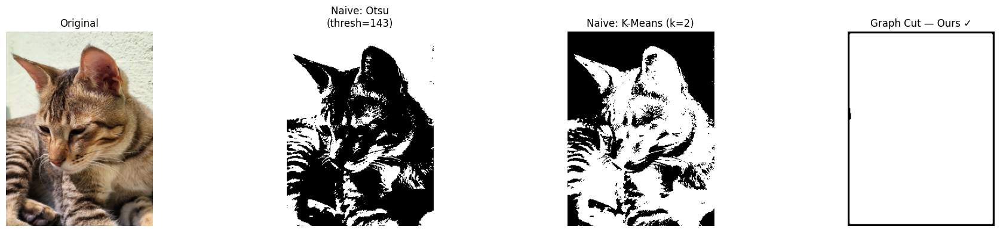

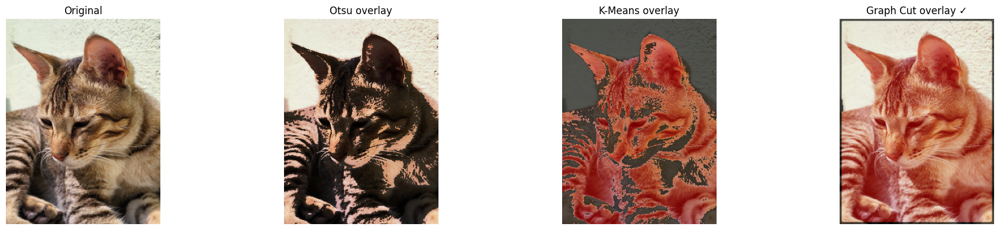

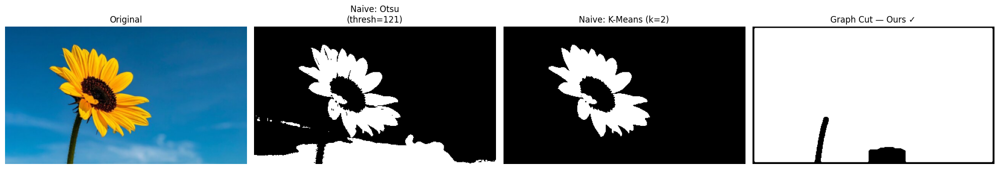

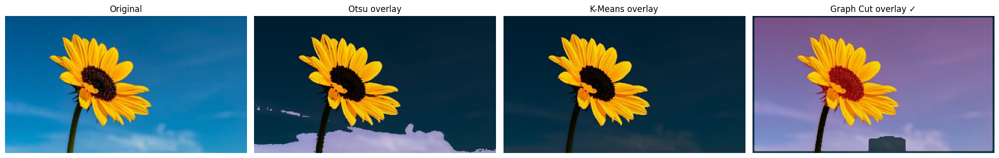

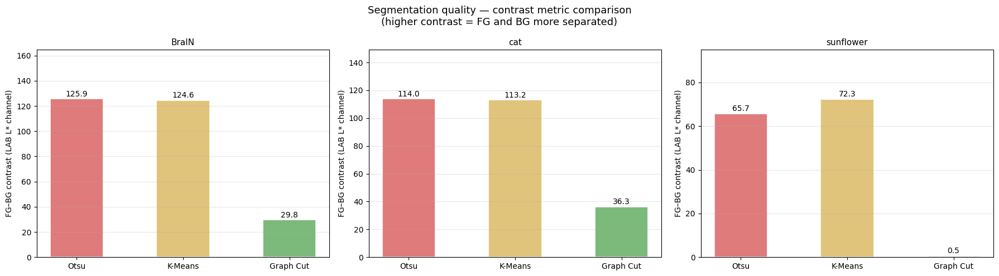


✅ Naive baseline complete. Proceed to Cell 10 for final comparison.


In [ ]:
# ============================================================
# CELL 9: Naive Segmentation — Otsu Thresholding Baseline
#
# WHY A BASELINE?
# ---------------
# To demonstrate the VALUE of graph cut we need something
# to compare against. Otsu thresholding is the simplest
# classic segmentation method:
#   1. Convert image to grayscale
#   2. Find optimal global threshold T that minimises
#      intra-class variance (Otsu's method)
#   3. Pixels > T → one class, pixels ≤ T → other class
#
# LIMITATIONS OF NAIVE THRESHOLDING vs GRAPH CUT
# -----------------------------------------------
#  ✗  No spatial smoothness — every pixel decided independently
#  ✗  Single global threshold — fails on uneven lighting
#  ✗  No user guidance — cannot distinguish FG from BG
#     when they have similar brightness
#  ✗  No iterative refinement — one-shot, no improvement
#
#  Graph cut addresses ALL of the above.
#
# WE ALSO INCLUDE:
#   • K-Means colour clustering (k=2) — slightly smarter
#     than Otsu but still no spatial constraint
#   • This gives THREE levels of comparison:
#       Naive (Otsu) < K-Means < Graph Cut (ours)
# ============================================================

from sklearn.cluster import KMeans

# ------------------------------------------------------------------
# Method 1: Otsu global thresholding
# ------------------------------------------------------------------
def naive_otsu_segment(image_bgr):
    """
    Segment using Otsu thresholding on grayscale.

    Returns
    -------
    mask  : H×W uint8  (1 = brighter class, 0 = darker class)
    thresh: int        Otsu threshold value found
    """
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    # cv2.THRESH_OTSU automatically finds optimal threshold T
    thresh_val, mask = cv2.threshold(
        gray, 0, 1,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    return mask.astype(np.uint8), int(thresh_val)


# ------------------------------------------------------------------
# Method 2: K-Means colour clustering (k=2 classes)
# ------------------------------------------------------------------
def naive_kmeans_segment(image_bgr, n_clusters=2, random_state=42):
    """
    Segment using K-Means clustering in LAB colour space.
    Assigns the cluster whose centre is closer to the image
    centre as foreground (heuristic).

    Returns
    -------
    mask : H×W uint8  (1 = foreground cluster, 0 = background)
    """
    h, w = image_bgr.shape[:2]

    # Work in LAB colour space (same as graph cut for fairness)
    lab      = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB).astype(float)
    pixels   = lab.reshape(-1, 3)

    km = KMeans(n_clusters=n_clusters, random_state=random_state,
                n_init=10)
    labels = km.fit_predict(pixels).reshape(h, w).astype(np.uint8)

    # Heuristic: the cluster containing the image centre = FG
    centre_label = labels[h // 2, w // 2]
    mask = (labels == centre_label).astype(np.uint8)
    return mask


# ------------------------------------------------------------------
# Helper: compute basic segmentation quality metrics
# (no ground truth needed — measures internal consistency)
# ------------------------------------------------------------------
def seg_metrics(image_bgr, mask):
    """
    Compute internal segmentation quality metrics.

    Returns dict with:
      fg_ratio     : fraction of image labelled FG
      mean_fg_L    : mean L* (lightness) of FG region in LAB
      mean_bg_L    : mean L* of BG region
      contrast     : |mean_fg_L - mean_bg_L|  (higher = better)
      boundary_len : perimeter length in pixels
    """
    lab     = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    L       = lab[:, :, 0].astype(float)
    fg_px   = L[mask == 1]
    bg_px   = L[mask == 0]
    kernel  = np.ones((3,3), np.uint8)
    boundary = cv2.dilate(mask, kernel) - cv2.erode(mask, kernel)

    return {
        'fg_ratio'    : mask.sum() / mask.size,
        'mean_fg_L'   : float(fg_px.mean()) if len(fg_px) else 0,
        'mean_bg_L'   : float(bg_px.mean()) if len(bg_px) else 0,
        'contrast'    : float(abs(fg_px.mean() - bg_px.mean()))
                        if len(fg_px) and len(bg_px) else 0,
        'boundary_len': int(boundary.sum()),
    }


# ---- Run both naive methods on all images ---------------------
naive_otsu_masks   = {}
naive_kmeans_masks = {}
all_metrics        = {}   # Stores metrics for all methods

for name, img in images_raw.items():
    print(f"\n[{name}]")

    # Otsu
    otsu_mask, otsu_thresh = naive_otsu_segment(img)
    naive_otsu_masks[name] = otsu_mask
    print(f"  Otsu threshold value : {otsu_thresh}")

    # K-Means
    km_mask = naive_kmeans_segment(img)
    naive_kmeans_masks[name] = km_mask
    print(f"  K-Means FG pixels    : {km_mask.sum()}")

    # Metrics for all three methods
    refined = refined_masks[name]
    m_otsu  = seg_metrics(img, otsu_mask)
    m_km    = seg_metrics(img, km_mask)
    m_gc    = seg_metrics(img, refined)
    all_metrics[name] = {'Otsu': m_otsu, 'K-Means': m_km, 'Graph Cut': m_gc}

    print(f"  {'Method':<12} {'FG ratio':>9} {'Contrast':>10} "
          f"{'Boundary':>10}")
    print(f"  {'-'*45}")
    for method, m in all_metrics[name].items():
        print(f"  {method:<12} {m['fg_ratio']:>9.3f} "
              f"{m['contrast']:>10.2f} {m['boundary_len']:>10d}")


# ---- Visualise all three methods side by side -----------------
for name, img in images_raw.items():
    otsu_ov = overlay_mask(img, naive_otsu_masks[name])
    km_ov   = overlay_mask(img, naive_kmeans_masks[name])
    gc_ov   = overlay_mask(img, refined_masks[name])

    show_images(
        [img,
         naive_otsu_masks[name] * 255,
         naive_kmeans_masks[name] * 255,
         refined_masks[name] * 255],
        ["Original",
         f"Naive: Otsu\n(thresh={naive_otsu_segment(img)[1]})",
         "Naive: K-Means (k=2)",
         "Graph Cut — Ours ✓"],
        figsize=(20, 4),
        cmap='gray'
    )

    show_images(
        [img, otsu_ov, km_ov, gc_ov],
        ["Original",
         "Otsu overlay",
         "K-Means overlay",
         "Graph Cut overlay ✓"],
        figsize=(20, 4)
    )


# ---- Bar chart: contrast metric comparison --------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Segmentation quality — contrast metric comparison\n"
             "(higher contrast = FG and BG more separated)", fontsize=13)

methods = ['Otsu', 'K-Means', 'Graph Cut']
colors  = ['#e07b7b', '#e0c47b', '#7bba7b']   # Red, amber, green

for ax, name in zip(axes, URLS):
    contrasts = [all_metrics[name][m]['contrast'] for m in methods]
    bars = ax.bar(methods, contrasts, color=colors, width=0.5,
                  edgecolor='white', linewidth=1.2)
    ax.set_title(name, fontsize=11)
    ax.set_ylabel("FG–BG contrast (LAB L* channel)")
    ax.set_ylim(0, max(contrasts) * 1.3 + 1)
    ax.grid(axis='y', alpha=0.3)
    # Annotate bar values
    for bar, val in zip(bars, contrasts):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.5,
                f"{val:.1f}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print("\n✅ Naive baseline complete. Proceed to Cell 10 for final comparison.")


[BraIN] Generating comparison figure ...


/tmp/ipykernel_19812/4147135828.py:110: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Patch(color='white',   label='Disagreement region',


  Saved: comparison_BraIN.png


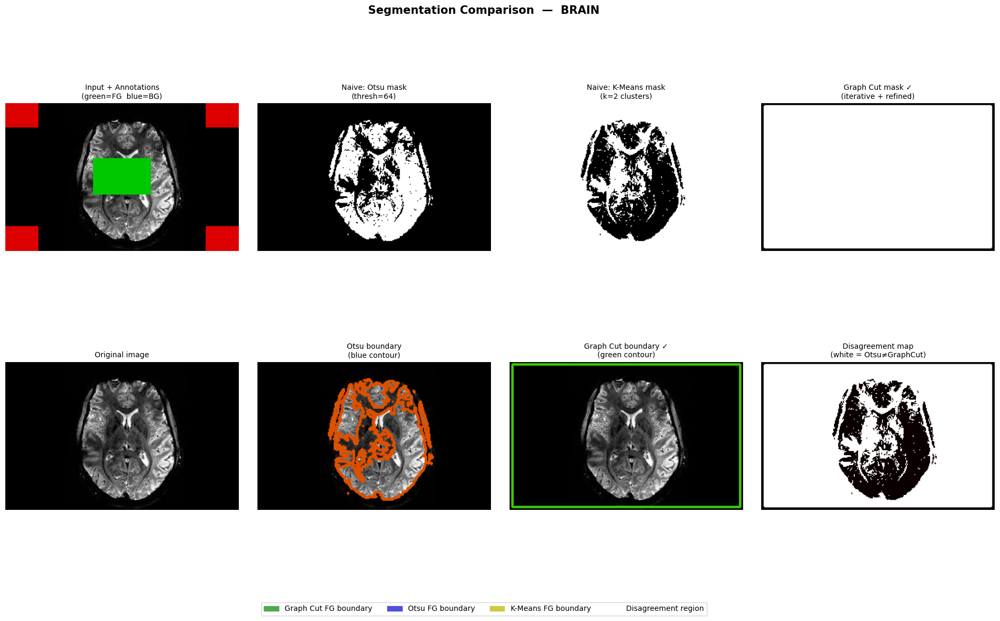


[cat] Generating comparison figure ...
  Saved: comparison_cat.png


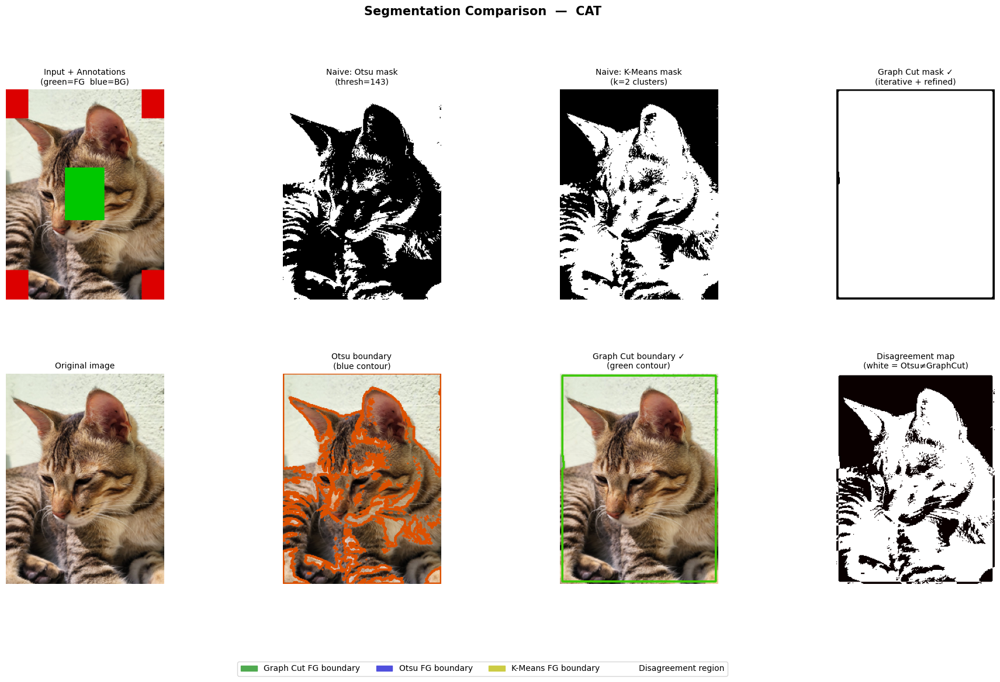


[sunflower] Generating comparison figure ...
  Saved: comparison_sunflower.png


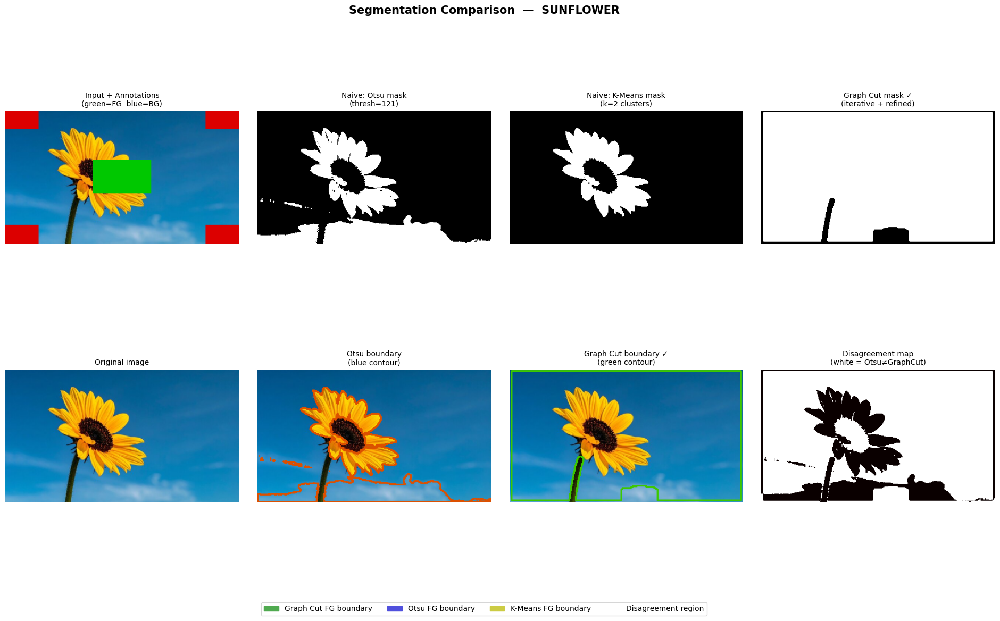


                         METRIC SUMMARY                        

  Image: BraIN
  Method            fg_ratio    contrastboundary_len
  --------------------------------------------------------
  Otsu                 0.184      125.88        7005
  K-Means              0.811      124.62        6931
  Graph Cut ✓          0.946       29.78        1796

  Image: cat
  Method            fg_ratio    contrastboundary_len
  --------------------------------------------------------
  Otsu                 0.426      113.98       15224
  K-Means              0.537      113.24       16571
  Graph Cut ✓          0.953       36.31        2060

  Image: sunflower
  Method            fg_ratio    contrastboundary_len
  --------------------------------------------------------
  Otsu                 0.225       65.70        5103
  K-Means              0.118       72.33        2707
  Graph Cut ✓          0.936        0.50        2916

  Higher contrast   = better FG/BG separation
  Lower boundary    = smo

In [ ]:
# ============================================================
# CELL 10: Final Comparison — Per-Image 8-Panel Figure
#
# For EACH image we produce a detailed 2×4 comparison grid:
#
#  Row 1 (masks):
#   [Original + seeds] [Otsu mask] [K-Means mask] [Graph Cut mask ✓]
#
#  Row 2 (overlays + analysis):
#   [Original]  [Otsu overlay]  [Graph Cut overlay ✓]  [Diff map]
#
# DIFF MAP explanation:
#   White pixels = labelled differently by Otsu vs Graph Cut
#   These are exactly the pixels where spatial smoothness
#   and GMM guidance made a difference.
#
# Each figure is saved as a PNG for your report.
# ============================================================

import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches

# ------------------------------------------------------------------
# Helper: draw clean boundary contour over image
# ------------------------------------------------------------------
def draw_boundary(image_bgr, mask, colour=(0, 255, 0), thickness=2):
    """
    Draw the segmentation boundary contour on a copy of the image.
    colour    : BGR tuple for contour colour
    thickness : line thickness in pixels
    """
    vis      = image_bgr.copy()
    mask_u8  = (mask * 255).astype(np.uint8)
    contours, _ = cv2.findContours(mask_u8, cv2.RETR_EXTERNAL,
                                   cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis, contours, -1, colour, thickness)
    return vis


# ------------------------------------------------------------------
# Helper: create the full 8-panel comparison figure for one image
# ------------------------------------------------------------------
def make_comparison_figure(name, image, fg_mask_seed, bg_mask_seed,
                           otsu_mask, km_mask, raw_mask, refined_mask):
    """
    Produce and save a 2×4 comparison figure.
    Returns the matplotlib Figure object.
    """
    # Prepare all panels
    annotated  = draw_seeds(image, fg_mask_seed, bg_mask_seed)
    otsu_ov    = overlay_mask(image, otsu_mask)
    gc_ov      = overlay_mask(image, refined_mask)

    # Boundary contour overlays
    otsu_cont  = draw_boundary(image, otsu_mask,    colour=(0, 80, 220))
    km_cont    = draw_boundary(image, km_mask,      colour=(220, 140, 0))
    gc_cont    = draw_boundary(image, refined_mask, colour=(0, 200, 60))

    # Difference map: pixels where Otsu and Graph Cut disagree
    diff       = np.abs(otsu_mask.astype(int) -
                        refined_mask.astype(int)).astype(np.uint8) * 255

    # ---- Build figure ------------------------------------------
    fig = plt.figure(figsize=(24, 11))
    fig.suptitle(f"Segmentation Comparison  —  {name.upper()}",
                 fontsize=15, fontweight='bold', y=1.01)

    gs = gridspec.GridSpec(2, 4, figure=fig,
                           hspace=0.35, wspace=0.08)

    panels_row1 = [
        (annotated,       "Input + Annotations\n(green=FG  blue=BG)"),
        (otsu_mask * 255, f"Naive: Otsu mask\n"
                          f"(thresh={naive_otsu_segment(image)[1]})"),
        (km_mask * 255,   "Naive: K-Means mask\n(k=2 clusters)"),
        (refined_mask*255,"Graph Cut mask ✓\n(iterative + refined)"),
    ]

    panels_row2 = [
        (image,     "Original image"),
        (otsu_cont, "Otsu boundary\n(blue contour)"),
        (gc_cont,   "Graph Cut boundary ✓\n(green contour)"),
        (diff,      "Disagreement map\n(white = Otsu≠GraphCut)"),
    ]

    for col, (img_panel, title) in enumerate(panels_row1):
        ax = fig.add_subplot(gs[0, col])
        if img_panel.ndim == 3:
            ax.imshow(cv2.cvtColor(img_panel, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img_panel,
                      cmap='RdYlGn' if 'Disagree' in title else 'gray')
        ax.set_title(title, fontsize=10, pad=6)
        ax.axis('off')

    for col, (img_panel, title) in enumerate(panels_row2):
        ax = fig.add_subplot(gs[1, col])
        if img_panel.ndim == 3:
            ax.imshow(cv2.cvtColor(img_panel, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img_panel, cmap='hot')
        ax.set_title(title, fontsize=10, pad=6)
        ax.axis('off')

    # Legend
    patches = [
        mpatches.Patch(color='#50aa50', label='Graph Cut FG boundary'),
        mpatches.Patch(color='#5050dd', label='Otsu FG boundary'),
        mpatches.Patch(color='#cccc44', label='K-Means FG boundary'),
        mpatches.Patch(color='white',   label='Disagreement region',
                       edgecolor='gray'),
    ]
    fig.legend(handles=patches, loc='lower center', ncol=4,
               fontsize=10, frameon=True,
               bbox_to_anchor=(0.5, -0.04))

    # Save
    fname = f"comparison_{name}.png"
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f"  Saved: {fname}")

    plt.show()
    return fig


# ---- Generate comparison figure for every image ---------------
comparison_figs = {}

for name, img in images_raw.items():
    fg_m, bg_m = seeds[name]
    print(f"\n[{name}] Generating comparison figure ...")
    fig = make_comparison_figure(
        name, img,
        fg_m, bg_m,
        naive_otsu_masks[name],
        naive_kmeans_masks[name],
        iter_results[name]['final_mask'],
        refined_masks[name]
    )
    comparison_figs[name] = fig


# ---- Comprehensive metrics summary table ----------------------
print("\n" + "=" * 65)
print(f"  {'METRIC SUMMARY':^61}")
print("=" * 65)

metric_keys = ['fg_ratio', 'contrast', 'boundary_len']
col_w = 12

for name in URLS:
    print(f"\n  Image: {name}")
    print(f"  {'Method':<14}" +
          "".join(f"{k:>{col_w}}" for k in metric_keys))
    print(f"  {'-'*56}")
    for method in ['Otsu', 'K-Means', 'Graph Cut']:
        m = all_metrics[name][method]
        marker = ' ✓' if method == 'Graph Cut' else '  '
        print(f"  {method+marker:<14}" +
              f"{m['fg_ratio']:>{col_w}.3f}"
              f"{m['contrast']:>{col_w}.2f}"
              f"{m['boundary_len']:>{col_w}d}")

print("\n" + "=" * 65)
print("  Higher contrast   = better FG/BG separation")
print("  Lower boundary    = smoother, less jagged boundary")
print("=" * 65)

print("\n✅ Per-image comparisons done. Proceed to Cell 11 for final figure.")